# Double descent — book graphics 1

Static matplotlib version of the `P8_15V2` manim scene in `p8_15.py`, for book SVGs.

Five panels, each saved as its own SVG (plus a PNG preview):

1. **Panels 1–4** — degree 1, 2, 3, 4 Legendre fits on top of the training points, testing points, and the underlying function $f(x) = \tfrac{1}{2}x^2$. Each is rendered twice: **clipped** to `YLIM`, and **unclipped** (y-range widened to contain the whole fit, with the same inches-per-data-unit scale, so the plot just gets taller).
2. **Panel 5** — training and testing MSE as a function of polynomial degree.

Axes are sized in inches directly (`AX_WIDTH_IN`, `AX_HEIGHT_IN` for the clipped y-range), so every panel shares one x-scale and one y-scale and they line up in Illustrator.

Data, seed, train/test split, and the pseudoinverse Legendre fit are identical to the manim scene, so the numbers match the video.


## 1. Config

In [1]:
import os
from pathlib import Path
import numpy as np
import scipy.special
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'   # from the CMYK swatch conversion (C76 M15 Y90 K2) — swap if you have a house value
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'

AXIS_COLOR   = CHILL_BROWN
CURVE_COLOR  = CHILL_BROWN   # underlying function f(x)
TRAIN_COLOR  = LT_BLUE
TEST_COLOR   = ORANGE
FIT_COLORS   = {1: GREEN, 2: BLUE, 3: RED, 4: PINK}

# ── Data (matches p8_15.py) ────────────────────────────────────────────────
RANDOM_SEED = 428
N_POINTS    = 10
NOISE_LEVEL = 0.2
TRAIN_FRAC  = 0.5
X_MIN, X_MAX = -2.0, 2.0
DEGREES     = [1, 2, 3, 4]
def f(x): return 0.5 * x**2

# ── Figure styling ─────────────────────────────────────────────────────────
AX_WIDTH_IN     = 4.0          # axes box width in inches (x-range XLIM maps onto this)
AX_HEIGHT_IN    = 3.4          # axes box height in inches for the clipped y-range YLIM;
                               # unclipped panels keep the same inches-per-unit and grow taller
MARGIN_IN       = 0.6          # whitespace around the axes box (tick labels live here)
LINEWIDTH       = 4.0      # fit lines + underlying curve
AXIS_LINEWIDTH  = 2.0
DOT_SIZE        = 100           # scatter marker area (pt^2)
FONTSIZE        = 20
XLIM            = (X_MIN, X_MAX)
YLIM            = (-0.5, 2.0)  # clipped y-range
UNCLIP_PAD      = 0.25         # data units of headroom above/below the fit in the unclipped version
X_TICK_STEP     = 1.0
Y_TICK_STEP     = 1.0          # for the curve-fit panels (clipped and unclipped)
MSE_YLIM        = None         # None = auto from data, or e.g. (0, 1.5)
MSE_LOG_Y       = False        # True for log-scale MSE axis (degree-4 train error is ~0, so it gets clipped)
MSE_SHOW_TRAIN  = True
MSE_SHOW_TEST   = True
SPINES          = 'lb'         # 'lb' = left+bottom only, 'box' = all four
SHOW_TICKS      = True         # False = bare axes (add numbers in Illustrator)
CURVE_ALPHA     = 0.5          # opacity of the underlying f(x) curve
CURVE_LINESTYLE = '-'          # e.g. '--' to dash the underlying function
SHOW_TEST_RESID = True         # dashed vertical line from each test point to the fit
RESID_LINEWIDTH = 2.4
RESID_DASH      = (1.2, 1.2)       # (dash length, gap length) in points
RESID_ALPHA     = 1.0
TRANSPARENT     = True

# ── Fonts: LaTeX / Computer Modern look ────────────────────────────────────
USE_TEX = True                # True = real LaTeX via text.usetex (needs a TeX install; text becomes outlines in the SVG)
plt.rcParams['font.family']  = 'serif'
plt.rcParams['font.serif']   = ['cmr10', 'Computer Modern Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.formatter.use_mathtext'] = True   # cmr10 has no proper minus sign; this routes tick labels through mathtext
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['text.usetex']  = USE_TEX
plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Illustrator

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/initial_curve_fits')   # relative to this notebook
SAVE    = True
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Fit helpers (from `p8_15.py`)

In [2]:
def fit_legendre_pinv(x_train, y_train, degree, x_min=X_MIN, x_max=X_MAX):
    """Fit Legendre polynomial using pseudoinverse."""
    x_scaled = 2 * (x_train - x_min) / (x_max - x_min) - 1
    feature_degrees = np.arange(degree + 1)[:, None]
    X_train_poly = scipy.special.eval_legendre(feature_degrees, x_scaled).T
    return np.linalg.pinv(X_train_poly) @ y_train

def eval_legendre_poly(beta, x, degree, x_min=X_MIN, x_max=X_MAX):
    """Evaluate Legendre polynomial with given coefficients."""
    x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
    feature_degrees = np.arange(degree + 1)[:, None]
    X_poly = scipy.special.eval_legendre(feature_degrees, x_scaled).T
    return X_poly @ beta

def get_noisy_data(n_points=N_POINTS, noise_level=NOISE_LEVEL, random_seed=RANDOM_SEED):
    np.random.seed(random_seed)
    x = np.random.uniform(X_MIN, X_MAX, n_points)
    y = f(x) + noise_level * np.random.randn(n_points)
    return x, y


## 3. Data + fits

In [3]:
x, y = get_noisy_data()
n_train = int(np.floor(N_POINTS * TRAIN_FRAC))
x_train, y_train = x[:n_train], y[:n_train]
x_test,  y_test  = x[n_train:], y[n_train:]

all_x = np.linspace(X_MIN, X_MAX, 256)
all_y = f(all_x)

fits = {}
for d in DEGREES:
    beta = fit_legendre_pinv(x_train, y_train, d)
    fits[d] = dict(
        beta      = beta,
        curve     = eval_legendre_poly(beta, all_x, d),
        train_mse = np.mean((y_train - eval_legendre_poly(beta, x_train, d))**2),
        test_mse  = np.mean((y_test  - eval_legendre_poly(beta, x_test,  d))**2),
    )

print(f"{'degree':>6} {'train MSE':>10} {'test MSE':>10} {'fit y-range':>22}")
for d in DEGREES:
    c = fits[d]['curve']
    print(f"{d:>6} {fits[d]['train_mse']:>10.6f} {fits[d]['test_mse']:>10.6f} {c.min():>10.2f} .. {c.max():<8.2f}")


degree  train MSE   test MSE            fit y-range
     1   0.221350   0.691636       0.49 .. 0.52    
     2   0.031825   0.079449      -0.06 .. 1.93    
     3   0.000803   0.727023      -0.67 .. 4.02    
     4   0.000000   1.328535      -2.33 .. 3.19    


## 4. Panel renderers

In [8]:
X_IN_PER_UNIT = AX_WIDTH_IN  / (XLIM[1] - XLIM[0])
Y_IN_PER_UNIT = AX_HEIGHT_IN / (YLIM[1] - YLIM[0])

def exact_axes(width_in, height_in, margin=MARGIN_IN):
    """Figure with a single axes box of exactly (width_in x height_in) inches."""
    fig = plt.figure(figsize=(width_in + 2 * margin, height_in + 2 * margin))
    ax = fig.add_axes([margin / fig.get_figwidth(), margin / fig.get_figheight(),
                       width_in / fig.get_figwidth(), height_in / fig.get_figheight()])
    return fig, ax

def style_ax(ax, color=AXIS_COLOR):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=FONTSIZE, width=AXIS_LINEWIDTH, which='both')
    ax.xaxis.label.set_color(color)
    ax.yaxis.label.set_color(color)
    if not SHOW_TICKS:
        ax.set_xticks([]); ax.set_yticks([])

def fit_ylim(degree, clip=True):
    """Clipped: YLIM. Unclipped: YLIM widened (never narrowed) to contain the whole fit."""
    if clip:
        return YLIM
    c = fits[degree]['curve']
    return (min(YLIM[0], c.min() - UNCLIP_PAD), max(YLIM[1], c.max() + UNCLIP_PAD))

def draw_fit_panel(ax, degree, clip=True):
    """Underlying curve + train/test points + a single fit of `degree`."""
    ylim = fit_ylim(degree, clip)
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=LINEWIDTH, ls=CURVE_LINESTYLE,
            alpha=CURVE_ALPHA, zorder=1, solid_capstyle='round')
    ax.plot(all_x, fits[degree]['curve'], color=FIT_COLORS[degree], lw=LINEWIDTH,
            zorder=4, solid_capstyle='round')
    if SHOW_TEST_RESID:
        y_fit_test = eval_legendre_poly(fits[degree]['beta'], x_test, degree)
        for xi, yi, yf in zip(x_test, y_test, y_fit_test):
            ax.plot([xi, xi], [yi, yf], color=ORANGE, lw=RESID_LINEWIDTH, #SW override color color=FIT_COLORS[degree],
                    ls=(0, RESID_DASH), alpha=RESID_ALPHA, zorder=2, dash_capstyle='butt')
    ax.scatter(x_train, y_train, s=DOT_SIZE, color=TRAIN_COLOR, zorder=3, linewidths=0)
    ax.scatter(x_test,  y_test,  s=DOT_SIZE, color=TEST_COLOR,  zorder=3, linewidths=0)
    ax.set_xlim(*XLIM); ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))
    style_ax(ax)

def fit_figure(degree, clip=True):
    """Standalone figure for one fit panel, sized so x- and y-scale match every other panel."""
    ylim = fit_ylim(degree, clip)
    fig, ax = exact_axes(AX_WIDTH_IN, (ylim[1] - ylim[0]) * Y_IN_PER_UNIT)
    draw_fit_panel(ax, degree, clip)
    return fig, ax

def draw_mse_panel(ax):
    """Train / test MSE vs polynomial degree (dots only)."""
    degs = np.array(DEGREES)
    tr   = np.array([fits[d]['train_mse'] for d in DEGREES])
    te   = np.array([fits[d]['test_mse']  for d in DEGREES])
    if MSE_SHOW_TRAIN:
        ax.scatter(degs, tr, s=DOT_SIZE, color=TRAIN_COLOR, zorder=3, linewidths=0)
    if MSE_SHOW_TEST:
        ax.scatter(degs, te, s=DOT_SIZE, color=TEST_COLOR, zorder=3, linewidths=0)
    ax.set_xlim(degs.min() - 0.5, degs.max() + 0.5)
    ax.set_xticks(degs)
    if MSE_LOG_Y:
        ax.set_yscale('log')
    elif MSE_YLIM is None:
        top = max(tr.max() if MSE_SHOW_TRAIN else 0, te.max() if MSE_SHOW_TEST else 0)
        ax.set_ylim(0, 1.1 * top)
    else:
        ax.set_ylim(*MSE_YLIM)
    style_ax(ax)

def mse_figure():
    fig, ax = exact_axes(AX_WIDTH_IN, AX_HEIGHT_IN)
    draw_mse_panel(ax)
    return fig, ax


## 5. Preview


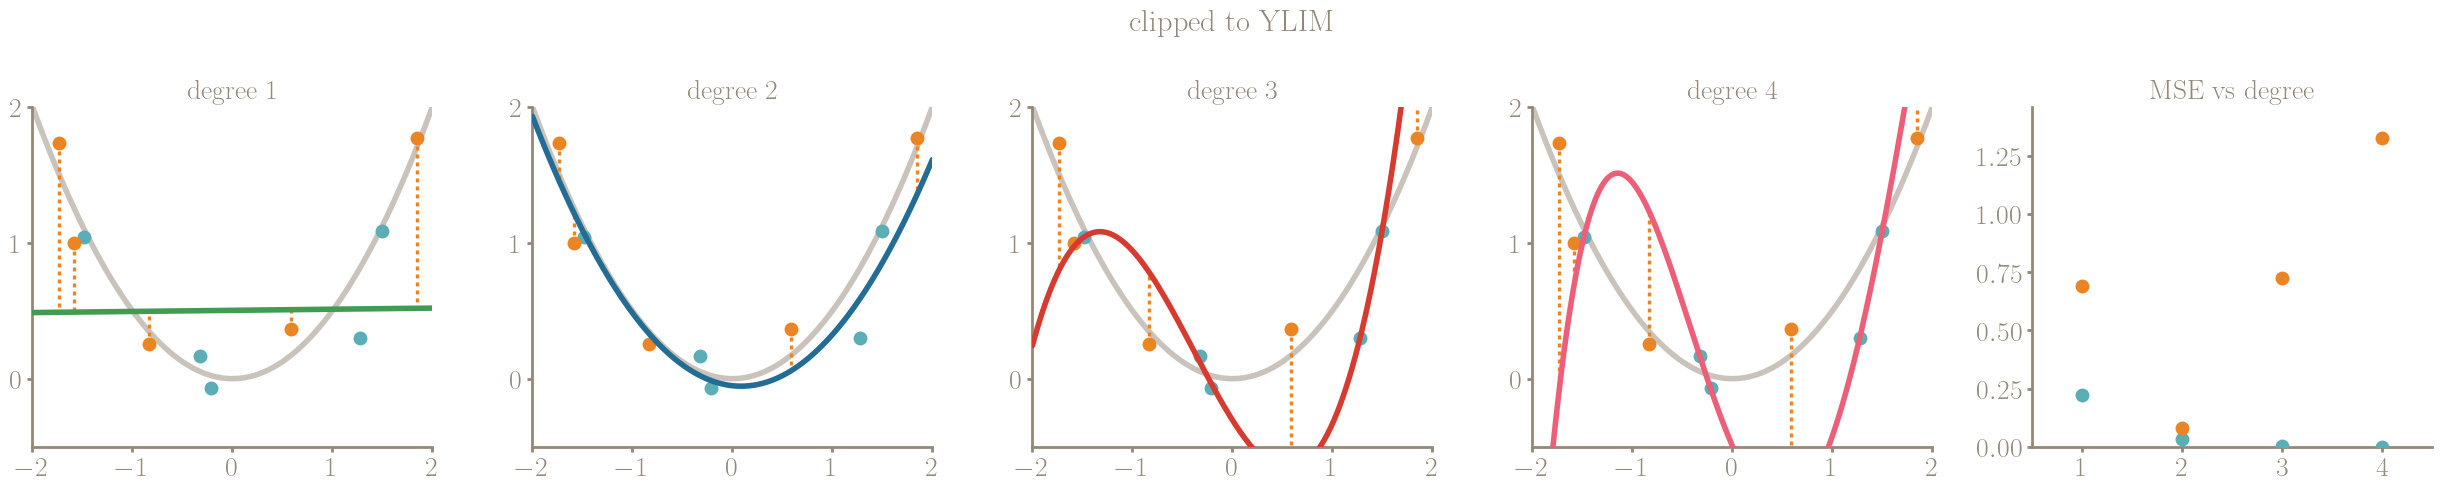

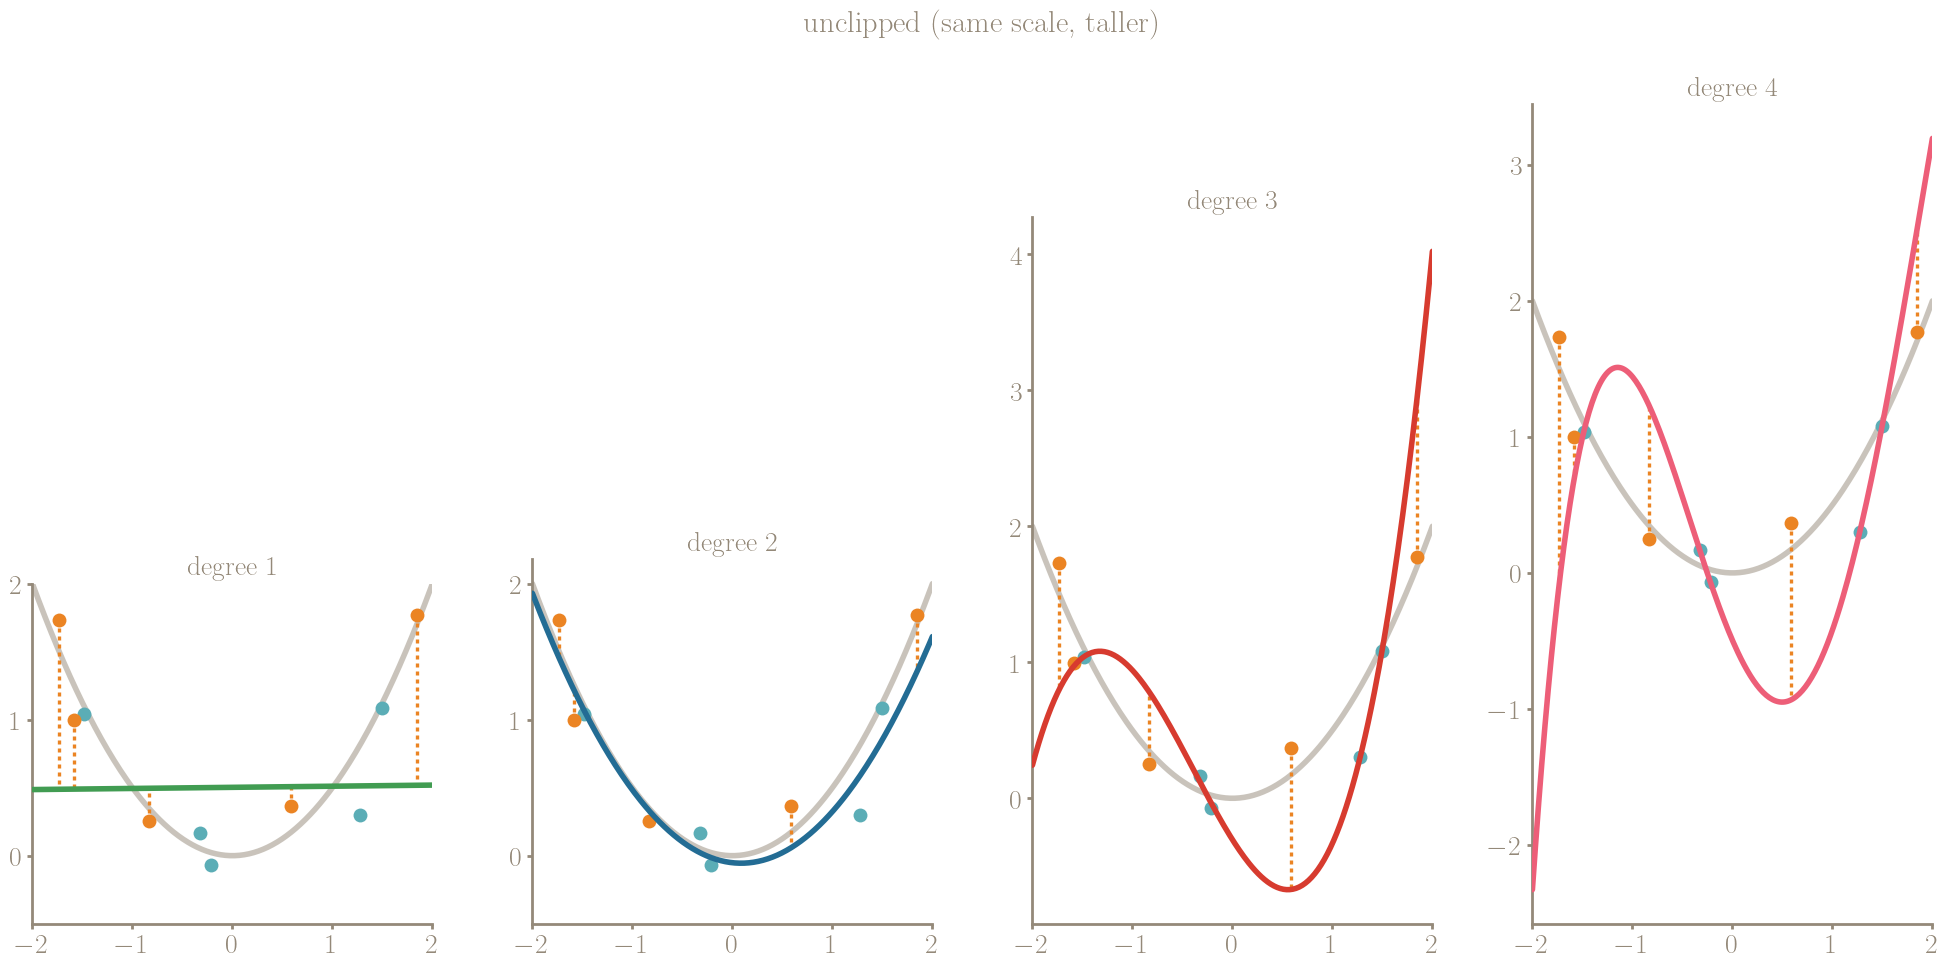

In [9]:
def preview_row(clip, title):
    """All four fit panels (+ MSE when clipped) side by side, bottom-aligned, at true relative size."""
    panels = [(d, clip) for d in DEGREES]
    sizes  = [(AX_WIDTH_IN, (fit_ylim(d, c)[1] - fit_ylim(d, c)[0]) * Y_IN_PER_UNIT) for d, c in panels]
    if clip:
        sizes.append((AX_WIDTH_IN, AX_HEIGHT_IN))
    gap = 1.0
    W = sum(w for w, _ in sizes) + gap * (len(sizes) + 1)
    H = max(h for _, h in sizes) + 2 * MARGIN_IN + 0.4
    fig = plt.figure(figsize=(W, H))
    x0 = gap
    for i, (w, h) in enumerate(sizes):
        ax = fig.add_axes([x0 / W, MARGIN_IN / H, w / W, h / H])
        if i < len(panels):
            d, c = panels[i]
            draw_fit_panel(ax, d, c)
            ax.set_title(f'degree {d}', color=AXIS_COLOR, fontsize=FONTSIZE)
        else:
            draw_mse_panel(ax)
            ax.set_title('MSE vs degree', color=AXIS_COLOR, fontsize=FONTSIZE)
        x0 += w + gap
    fig.suptitle(title, color=AXIS_COLOR, fontsize=FONTSIZE + 2, y=0.995)
    plt.show()

preview_row(clip=True,  title='clipped to YLIM')
preview_row(clip=False, title='unclipped (same scale, taller)')


## 6. Export — one SVG (+ PNG) per panel

In [10]:
def save(fig, stem):
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, transparent=TRANSPARENT, bbox_inches='tight')
    plt.close(fig)

if SAVE:
    for d in DEGREES:
        fig, _ = fit_figure(d, clip=True);  save(fig, f'panel_{d}_degree_{d}_fit')
        fig, _ = fit_figure(d, clip=False); save(fig, f'panel_{d}_degree_{d}_fit_unclipped')
    fig, _ = mse_figure(); save(fig, 'panel_5_mse_vs_degree')

    print('saved to', OUT_DIR.resolve())
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/initial_curve_fits
   panel_1_degree_1_fit.svg
   panel_1_degree_1_fit_unclipped.svg
   panel_2_degree_2_fit.svg
   panel_2_degree_2_fit_unclipped.svg
   panel_3_degree_3_fit.svg
   panel_3_degree_3_fit_unclipped.svg
   panel_4_degree_4_fit.svg
   panel_4_degree_4_fit_unclipped.svg
   panel_5_mse_vs_degree.svg


In [7]:
OUT_DIR

PosixPath('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/initial_curve_fits')